In [1]:
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    temperature=0.2,
    timeout=60,
    max_retries=5
)


c:\Users\imfaz\Downloads\langraph tut\myenv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'ErgDCrUDAWkUfROaupMq/jGbL2KzUiKU/nsWrIimm/LsRmah6Qctqt2g9dLhf24T20CT3GsBLWZeUJFFeE9PxElpOcMtQZcJHVOvVK+jXYGVTA/w21QOae+mpYT991wYHaQBa7gfAgpuPNHpkElrBl9Hutt3iP59Rypz+ni9wszoY6JCpmoK4y6uGbiqi/z+h5HloHzc4e58kPpqiPF2NpTW9v2OkYlE9c/OIG0uFeDcMvsrr76YnblKqFuLtloOYk//u/KnePGT0JEVph7C9QimfcYwQD0BMDH5oactajQQaWQE+ULW086qZG31BlNuwTK21e6iq1LAEmlSED8V4fVG5Lm4Kfj83L6/o3+gZmfAWgy9cpLq187iZNSPkjt+QV4sj2Aw+p/ZAnNdHd/77Q+BiebzCK9e3uKdXKZPOViEzY4TKUsYyouEnU8/4OMSLSOe9UZLwoGcIQpLmptPm6WGm7jQTW4I9FQQFF1dGauzAttv1ih3n9nS0wmcDvk9ZiFKnHcdk75YfnRLg6S8c8hltF7u+WcEaJW3yWbdHVIiIsLnzk7GhASjmA2rLjE5YH0MPzyMe/NfmFY='}}]


In [4]:
class LLMState(TypedDict):
    question:str
    answer:str

In [5]:
def llm_qa(state:LLMState)->LLMState:
    question=state["question"]
    prompt=f"Answer the following Question? {question}"
    answer=model.invoke(prompt).content
    state['answer']=answer
    return state

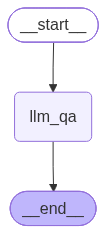

In [6]:
graph=StateGraph(LLMState)

graph.add_node('llm_qa',llm_qa)

graph.add_edge(START,'llm_qa')

graph.add_edge('llm_qa',END)

workflow=graph.compile()
workflow


In [7]:
initial_state={"question":"who is the greatest football player of all time?"}
output_state= workflow.invoke(initial_state)
output_state

c:\Users\imfaz\Downloads\langraph tut\myenv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'question': 'who is the greatest football player of all time?',
 'answer': [{'type': 'text',
   'text': 'Determining the "greatest football (soccer) player of all time" (the **GOAT**) is one of the most fiercely debated topics in sports. Because different eras, playing styles, and achievements are hard to compare directly, there is no single objective answer. \n\nHowever, the consensus among most experts, players, and fans points to four main contenders, with **Lionel Messi** currently holding the strongest overall case for most people.\n\nHere is a breakdown of the top candidates and why they are in the conversation:\n\n---\n\n### 1. Lionel Messi (Argentina) – *The Complete Modern Footballer*\nSince winning the **2022 FIFA World Cup**, Messi has become the definitive choice for a majority of football analysts and fans. \n* **Key Achievements:** 1 World Cup, 8 Ballon d\'Or awards (most in history), 4 Champions League titles, 10 La Liga titles, Copa América.\n* **Why He\'s the GOAT:** 